# Task 1: Neural Network Fundamentals



## Objective
The Objective is to understand the fundamentals of neural networks and implement a simple neural network using TensorFlow/Keras to classify handwritten digits from the MNIST dataset.



In [6]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

print("Tensorflow version:", tf.__version__)

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training Image:", x_train.shape) # it returns (total no. of images, pixel, pixel)
print("Training Label:", y_train.shape)
print("Testing Image:", x_test.shape)
print("Testing Label:", y_test.shape)


Tensorflow version: 2.21.0
Training Image: (60000, 28, 28)
Training Label: (60000,)
Testing Image: (10000, 28, 28)
Testing Label: (10000,)


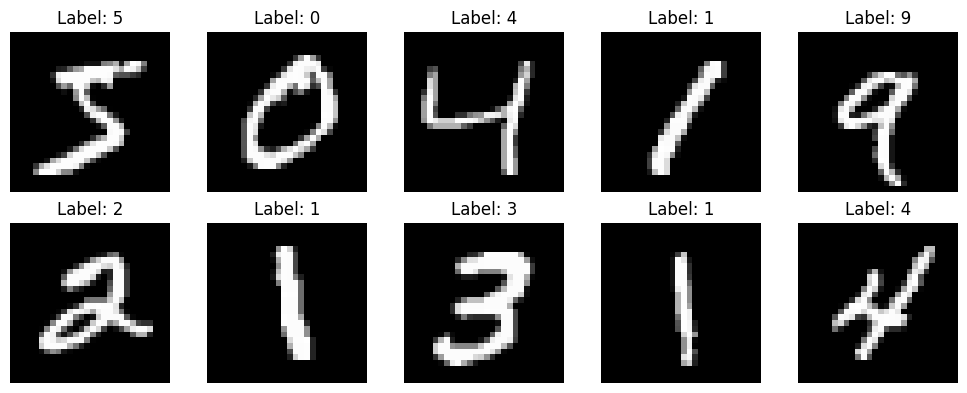

In [7]:
plt.figure(figsize=(10,4))

for i in range(10):
  plt.subplot(2, 5, i+1)
  plt.imshow(x_train[i], cmap='gray')
  plt.title(f"Label: {y_train[i]}")
  plt.axis('off')

plt.tight_layout()
plt.show()

In [9]:
print(x_train.dtype)

uint8


In [10]:
# Normalising data by dividing values by 255
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [11]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(
  optimizer="adam",
  loss="sparse_categorical_crossentropy",
  metrics=["accuracy"]
)

history = model.fit(
  x_train,
  y_train,
  epochs=5,
  batch_size=32,
  validation_split=0.1
)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9221 - loss: 0.2693 - val_accuracy: 0.9673 - val_loss: 0.1192
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9643 - loss: 0.1188 - val_accuracy: 0.9730 - val_loss: 0.0928
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9752 - loss: 0.0818 - val_accuracy: 0.9745 - val_loss: 0.0830
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9818 - loss: 0.0601 - val_accuracy: 0.9773 - val_loss: 0.0761
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9859 - loss: 0.0463 - val_accuracy: 0.9763 - val_loss: 0.0793


In [14]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.0770
Test Accuracy: 97.56%


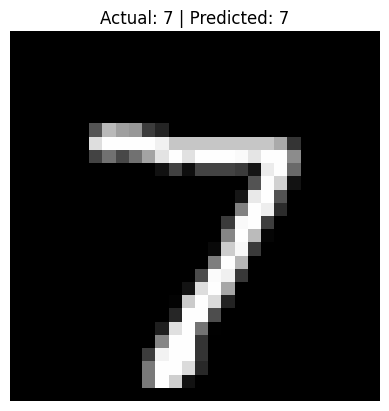

Actual digit: 7
Predicted digit: 7
Confidence: 99.33%


In [17]:
# Prediction

index = 0

image = x_test[index]
actual_digit = y_test[index]

prediction = model.predict(image.reshape(1, 28, 28), verbose=0)
predicted_digit = np.argmax(prediction[0])

plt.imshow(image, cmap="gray")
plt.title(
  f"Actual: {actual_digit} | Predicted: {predicted_digit}"
)
plt.axis("off")
plt.show()

print("Actual digit:", actual_digit)
print("Predicted digit:", predicted_digit)
print(f"Confidence: {prediction[0][predicted_digit] * 100:.2f}%")


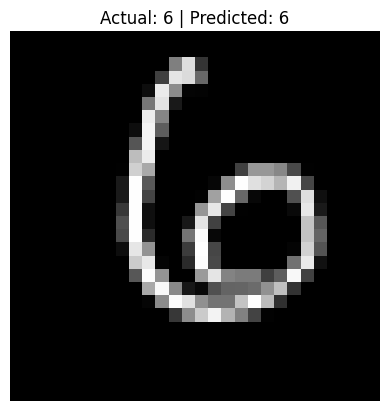

Actual digit: 6
Predicted digit: 6
Confidence: 99.99%


In [20]:

index = 100

image = x_test[index]
actual_digit = y_test[index]

prediction = model.predict(image.reshape(1, 28, 28), verbose=0)
predicted_digit = np.argmax(prediction[0])

plt.imshow(image, cmap="gray")
plt.title(
  f"Actual: {actual_digit} | Predicted: {predicted_digit}"
)
plt.axis("off")
plt.show()

print("Actual digit:", actual_digit)
print("Predicted digit:", predicted_digit)
print(f"Confidence: {prediction[0][predicted_digit] * 100:.2f}%")


## Comparing the result by changing the activation function

In [15]:

model_tanh = tf.keras.Sequential([
  tf.keras.Input(shape=(28, 28)),
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(128, activation="tanh"),
  tf.keras.layers.Dense(10, activation="softmax")
])

model_tanh.compile(
  optimizer="adam",
  loss="sparse_categorical_crossentropy",
  metrics=["accuracy"]
)

history_tanh = model_tanh.fit(
  x_train,
  y_train,
  epochs=5,
  batch_size=32,
  validation_split=0.1,
  verbose=1
)

tanh_loss, tanh_accuracy = model_tanh.evaluate(
  x_test, y_test, verbose=0
)

print(f"Tanh Test Loss: {tanh_loss:.4f}")
print(f"Tanh Test Accuracy: {tanh_accuracy * 100:.2f}%")


Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9152 - loss: 0.2976 - val_accuracy: 0.9607 - val_loss: 0.1472
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9584 - loss: 0.1439 - val_accuracy: 0.9708 - val_loss: 0.1013
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9713 - loss: 0.0973 - val_accuracy: 0.9743 - val_loss: 0.0841
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9793 - loss: 0.0719 - val_accuracy: 0.9777 - val_loss: 0.0737
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9844 - loss: 0.0542 - val_accuracy: 0.9770 - val_loss: 0.0764
Tanh Test Loss: 0.0813
Tanh Test Accuracy: 97.51%


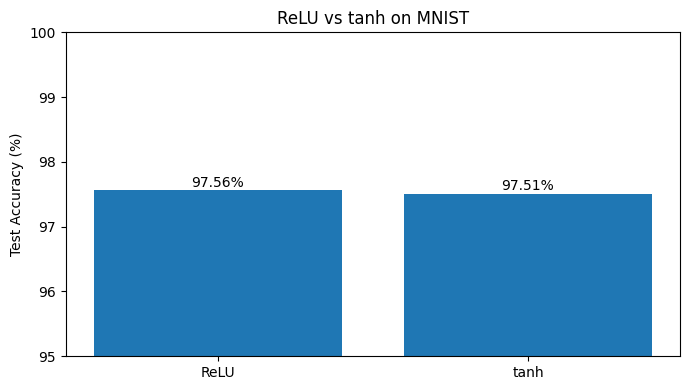

In [16]:
# Visualizing the comparison between ReLU and Tanh activation function

activations = ["ReLU", "tanh"]
accuracies = [97.56, 97.51]

plt.figure(figsize=(7, 4))
bars = plt.bar(activations, accuracies)

plt.ylabel("Test Accuracy (%)")
plt.title("ReLU vs tanh on MNIST")
plt.ylim(95, 100)

for bar, accuracy in zip(bars, accuracies):
  plt.text(
    bar.get_x() + bar.get_width() / 2,
    bar.get_height() + 0.05,
    f"{accuracy:.2f}%",
    ha="center"
  )

plt.tight_layout()
plt.show()
